# One-bit operators

Notebook 00 gave us two operations on a bit: set it to 1 and clear it to 0. A
program needs more than that. It must be able to leave a bit alone, flip a
bit whatever its value, and ask whether a bit is 1. Each of these is a
$2\times2$ matrix, and each can be built out of the set and clear operations.

This notebook builds them one at a time. Along the way it introduces a
shorthand for writing matrices out of basis states, which the rest of the
course uses constantly.

## Before you start

This notebook assumes [Notebook 00](00_Bits_and_Basis_States.ipynb): the basis
states $|0\rangle = (1,0)^T$ and $|1\rangle = (0,1)^T$, the creation operator
$a^\dagger$ (sets a bit) and the annihilation operator $a$ (clears a bit), and
the Encoding, Operator, Execution and Analysis steps for running a circuit
with the Sampler.

Quick check:

1. What is $a\,|1\rangle$? What is $a^\dagger|1\rangle$?
2. What is $a\,a^\dagger|0\rangle$?
3. A circuit applies NOT to qubit 1 of a two-qubit register and measures.
   Which counts key does every shot return?

Answers: $|0\rangle$ and the zero vector $0$; $|0\rangle$; `"10"` (qubit 0 is
the rightmost character).

After this notebook you will be able to:

1. Build, from the set and clear operations, a matrix that reports whether a
   bit is 1 and a matrix that leaves every bit unchanged.
2. Derive the matrix of NOT from the set and clear operations, and show that
   applying NOT twice changes nothing.
3. Derive a matrix that multiplies a bit by $+1$ or $-1$ according to its
   value, and explain why that sign change does not show up in the counts.
4. Predict the counts returned by a circuit made of these operations, and
   check the prediction on the simulator.

## Setup

This cell loads the libraries and decides where circuits run (the simulator
only, unless you change `skip_hardware`).

In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace

import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Operator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# _runtime.py (in ../scripts) decides where circuits run:
# the Aer simulator, plus IBM hardware if asked.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _runtime import get_targets

np.set_printoptions(precision=3, suppress=True)

SETTINGS = SimpleNamespace(
    shots=4096,                  # runs of each circuit
    precision=0.02,              # used from Notebook 09 on
    backend="ibm_rensselaer",
    name="default",              # saved IBM account name
    skip_hardware=True,          # set to False to also run on IBM hardware
    poll_interval=20,            # seconds between hardware status checks
)
targets = get_targets(SETTINGS)
print("Running on:", [t.label for t in targets])

Running on: ['aer']


## Operators, bras, and outer products

Every operation in this unit is a square matrix that acts on the vectors of
Notebook 00. Such a matrix is an *operator*. For one bit an operator is a
$2\times2$ matrix; for $n$ bits it is $2^n \times 2^n$.

When an expression contains several operators, the one written next to the
ket acts first. In $A\,B\,|v\rangle$, first $B$ acts on $|v\rangle$, then $A$
acts on the result, because $A\,B\,|v\rangle = A\,(B\,|v\rangle)$. Notebook 00
used this rule in Example 2 without naming it.

Writing operators as grids of numbers hides what they do. A shorthand built
from basis states shows it directly. It needs two new pieces of notation.

The *bra* $\langle v|$ is the transpose of the ket $|v\rangle$: the same
numbers written as a row. For example, $\langle 1| = (0, 1)$. All vectors in
Notebooks 00 to 03 have real entries; Notebook 04 extends the definition to
complex entries.

A bra times a ket is a row times a column, which is a single number. This
number is the *inner product* $\langle u|v\rangle$. For basis states,

$$\langle 0|0\rangle = 1, \qquad \langle 1|1\rangle = 1, \qquad \langle 0|1\rangle = \langle 1|0\rangle = 0.$$

In words: the inner product of a basis state with itself is 1, and with the
other basis state is 0.

A ket times a bra is a column times a row, which is a matrix. This matrix is
the *outer product* $|u\rangle\langle v|$. It acts on a ket $|w\rangle$ by

$$\big(|u\rangle\langle v|\big)\,|w\rangle = |u\rangle\,\langle v|w\rangle,$$

that is, it computes the number $\langle v|w\rangle$ and multiplies $|u\rangle$
by it. In words: $|u\rangle\langle v|$ turns $|v\rangle$ into $|u\rangle$.

### Example 1: the annihilation operator as an outer product

**Problem.** Show that $a = |0\rangle\langle 1|$, both by computing the matrix
and by checking what it does to each basis state.

**Plan.** Multiply the column $|0\rangle$ by the row $\langle 1|$. Then use the
rule $\big(|u\rangle\langle v|\big)|w\rangle = |u\rangle\langle v|w\rangle$ on
$|0\rangle$ and on $|1\rangle$.

**Solution.**

**Subgoal 1: compute the matrix.**

1. Write the column and the row: $|0\rangle = (1, 0)^T$ and
   $\langle 1| = (0, 1)$.
2. Entry $(i, j)$ of a column times a row is (entry $i$ of the column) times
   (entry $j$ of the row). The only nonzero product is $1 \times 1$ in row 0,
   column 1:
   $$|0\rangle\langle 1| = \begin{pmatrix}1\\0\end{pmatrix}\begin{pmatrix}0&1\end{pmatrix} = \begin{pmatrix}0&1\\0&0\end{pmatrix}.$$
3. This is the matrix of $a$ from Notebook 00.

**Subgoal 2: check the action on each basis state.**

4. On $|1\rangle$: $|0\rangle\langle 1|1\rangle = |0\rangle \times 1 = |0\rangle$.
5. On $|0\rangle$: $|0\rangle\langle 1|0\rangle = |0\rangle \times 0 = 0$, the
   zero vector.

**Check.** Steps 4 and 5 match $a|1\rangle = |0\rangle$ and $a|0\rangle = 0$
from Notebook 00. The same calculation with the roles swapped gives
$a^\dagger = |1\rangle\langle 0|$.

**Takeaway.** The operator $|u\rangle\langle v|$ is read right to left: it
looks for $|v\rangle$ and replaces it with $|u\rangle$. So $a = |0\rangle\langle 1|$
("replace 1 by 0") and $a^\dagger = |1\rangle\langle 0|$ ("replace 0 by 1").

In [2]:
ket0 = np.array([1, 0])
ket1 = np.array([0, 1])

a = np.outer(ket0, ket1)       # |0><1|
a_dag = np.outer(ket1, ket0)   # |1><0|
print("|0><1| =\n", a)
print("|1><0| =\n", a_dag)
print("a |1> =", a @ ket1, "  a |0> =", a @ ket0)

|0><1| =
 [[0 1]
 [0 0]]
|1><0| =
 [[0 0]
 [1 0]]
a |1> = [1 0]   a |0> = [0 0]


**Check.** Which outer product leaves $|0\rangle$ as it is and sends
$|1\rangle$ to the zero vector?

## The number operator and projectors

How can a matrix ask whether a bit is 1? Try the two operators in sequence:
first clear, then set. On $|1\rangle$, clearing gives $|0\rangle$ and setting
gives $|1\rangle$ back. On $|0\rangle$, clearing already fails and gives $0$.
So the product $a^\dagger a$ keeps $|1\rangle$ and removes $|0\rangle$.

The *number operator* is

$$n = a^\dagger a.$$

### Example 2: the matrix of the number operator

**Problem.** Compute the matrix of $n = a^\dagger a$, and find $n|0\rangle$
and $n|1\rangle$.

**Plan.** Multiply the two outer products from Example 1 and use
$\langle 0|0\rangle = 1$. Then act on each basis state.

**Solution.**

**Subgoal 1: multiply the outer products.**

1. Substitute $a^\dagger = |1\rangle\langle 0|$ and $a = |0\rangle\langle 1|$:
   $n = |1\rangle\langle 0|\,|0\rangle\langle 1|$.
2. The middle pair is the inner product $\langle 0|0\rangle = 1$, so
   $n = |1\rangle\langle 1|$.
3. As a matrix, $|1\rangle\langle 1| = \begin{pmatrix}0\\1\end{pmatrix}\begin{pmatrix}0&1\end{pmatrix} = \begin{pmatrix}0&0\\0&1\end{pmatrix}$.

**Subgoal 2: act on the basis states.**

4. $n|0\rangle = |1\rangle\langle 1|0\rangle = |1\rangle \times 0 = 0$.
5. $n|1\rangle = |1\rangle\langle 1|1\rangle = |1\rangle \times 1 = |1\rangle$.

**Check.** Both results fit one formula: $n|x\rangle = x\,|x\rangle$ for
$x = 0$ and $x = 1$. The matrix is diagonal with the bit values 0 and 1 on
the diagonal.

**Self-explanation prompt.** In step 2, why may we replace
$\langle 0|\,|0\rangle$ by the number 1 in the middle of a product of
matrices? **Answer.** Matrix multiplication is associative, so we may first
multiply the row $\langle 0|$ by the column $|0\rangle$, which gives the
$1\times1$ matrix $(1)$, and a $1\times 1$ factor of 1 changes nothing.

**Takeaway.** $n|x\rangle = x|x\rangle$: each basis state is an eigenvector of
$n$, and the eigenvalue is the value of the bit. The number operator reads
the bit.

The name comes from the physics reading in Notebook 00: if a 1 means "a
particle is here", then $n$ counts the particles on this bit, 0 or 1.

The product in the other order, $\bar n = a\,a^\dagger$, does the opposite.
The same steps as Example 2 give
$a\,a^\dagger = |0\rangle\langle 1|\,|1\rangle\langle 0| = |0\rangle\,\langle 1|1\rangle\,\langle 0| = |0\rangle\langle 0|$,
so

$$\bar n = a\,a^\dagger = |0\rangle\langle 0| = \begin{pmatrix}1&0\\0&0\end{pmatrix}, \qquad \bar n|x\rangle = (1 - x)\,|x\rangle.$$

In words: $\bar n$ keeps $|0\rangle$ and removes $|1\rangle$. It answers
"is this bit 0?".

Both $n$ and $\bar n$ keep one basis state unchanged and remove the other.
Doing that twice is the same as doing it once. A matrix $P$ with this property,

$$P^2 = P,$$

is a *projector*. In words: a projector keeps the part of a vector that lies
along some direction and removes the rest, so applying it a second time finds
nothing more to remove. For $n$: $n^2 = |1\rangle\langle 1|1\rangle\langle 1| = |1\rangle\langle 1| = n$.

The two projectors together cover everything. Adding them,

$$n + \bar n = \begin{pmatrix}0&0\\0&1\end{pmatrix} + \begin{pmatrix}1&0\\0&0\end{pmatrix} = I,$$

where $I$ is the $2\times2$ identity, the operator that leaves every bit
unchanged. This equation, $I = n + \bar n$, is the *completeness* relation. In
words: a bit is either 1 or 0, so "keep it if it is 1" plus "keep it if it is
0" keeps everything. Notebook 02 uses this relation to split an operator into
"what to do when the bit is 0" and "what to do when the bit is 1".

In [3]:
n = a_dag @ a
n_bar = a @ a_dag
I = np.eye(2, dtype=int)
print("n =\n", n)
print("n_bar =\n", n_bar)
print("n @ n == n:", np.array_equal(n @ n, n))
print("n_bar @ n_bar == n_bar:", np.array_equal(n_bar @ n_bar, n_bar))
print("n + n_bar == I:", np.array_equal(n + n_bar, I))

n =
 [[0 0]
 [0 1]]
n_bar =
 [[1 0]
 [0 0]]
n @ n == n: True
n_bar @ n_bar == n_bar: True
n + n_bar == I: True


A common mistake is to think that $a^\dagger a = I$, because setting a bit
undoes clearing it. That is wrong: $a^\dagger a = n$, which sends $|0\rangle$
to the zero vector. Clearing a bit that is already 0 fails, and setting
afterward cannot repair the failure. The mistake is tempting because it is
true on the one input, $|1\rangle$, where clearing succeeds. The correct
statement combines both orders: $a^\dagger a + a\,a^\dagger = n + \bar n = I$.

**Check.** What is $n\,\bar n$, and what does the answer say about asking
"is the bit 1?" and "is the bit 0?" one after the other?

## NOT: the Pauli X operator

Setting works only on a 0, and clearing works only on a 1. NOT must work on
both: it should set a 0 and clear a 1. The zero vectors from Notebook 00 make
this possible. On $|0\rangle$, the operator $a$ gives 0, so adding $a$ to
$a^\dagger$ changes nothing there; on $|1\rangle$, the operator $a^\dagger$
gives 0, so adding it to $a$ changes nothing there. The sum does the right
thing on each input.

The NOT operator is

$$X = a + a^\dagger = |0\rangle\langle 1| + |1\rangle\langle 0| = \begin{pmatrix}0&1\\1&0\end{pmatrix}.$$

In words: $X$ replaces 1 by 0 and 0 by 1. It is called *Pauli X*, after the
physicist Wolfgang Pauli; it is one of three *Pauli operators*. This notebook
also builds the second, $Z$. The third, $Y$, needs complex numbers and
appears in Notebook 04. Qiskit's name for the NOT gate, `x`, comes from this
operator.

### Example 3: NOT twice changes nothing

**Problem.** Show that $X^2 = I$ using only the rules of $a$ and $a^\dagger$.

**Plan.** Expand $(a + a^\dagger)^2$ into four products, then evaluate each
with results from Notebook 00 and this notebook.

**Solution.**

**Subgoal 1: expand the square.**

1. Multiply out, keeping the order of each product (matrices need not
   commute): $X^2 = (a + a^\dagger)(a + a^\dagger) = a\,a + a\,a^\dagger + a^\dagger a + a^\dagger a^\dagger$.

**Subgoal 2: evaluate each product.**

2. $a\,a = 0$: clearing twice fails on every input (Notebook 00,
   Exercise 3).
3. $a^\dagger a^\dagger = 0$: setting twice fails on every input (the same
   exercise).
4. $a\,a^\dagger = \bar n$ and $a^\dagger a = n$ (the previous section).

**Subgoal 3: add the pieces.**

5. Substitute: $X^2 = 0 + \bar n + n + 0$.
6. Use completeness, $n + \bar n = I$: $X^2 = I$.

**Check.** Multiply the matrices directly:
$\begin{pmatrix}0&1\\1&0\end{pmatrix}\begin{pmatrix}0&1\\1&0\end{pmatrix} = \begin{pmatrix}1&0\\0&1\end{pmatrix}$.
The two methods agree.

**Takeaway.** $X$ is its own inverse: flipping a bit twice restores it. Each
term of the expansion has a meaning: "set then clear" survives on 0, "clear
then set" survives on 1, and the two impossible double operations vanish.

In [4]:
X = a + a_dag
print("X =\n", X)
print("X |0> =", X @ ket0, "  X |1> =", X @ ket1)
print("X @ X == I:", np.array_equal(X @ X, I))

X =
 [[0 1]
 [1 0]]
X |0> = [0 1]   X |1> = [1 0]
X @ X == I: True


**Check.** Is $X$ a projector? Use the definition $P^2 = P$.

## The Pauli Z operator and the Z-basis measurement

The number operator reads a bit as 0 or 1. Many problems are easier to write
with the bit read as $+1$ or $-1$ instead, for example a magnet pointing up or
down, or a node of a network placed in one of two groups. An operator that does this
should multiply $|0\rangle$ by $+1$ and $|1\rangle$ by $-1$.

The projectors do this directly: keep $|0\rangle$ with a plus sign and keep
$|1\rangle$ with a minus sign. The operator *Pauli Z* is

$$Z = \bar n - n = \begin{pmatrix}1&0\\0&-1\end{pmatrix}.$$

In words: $Z$ leaves $|0\rangle$ alone and multiplies $|1\rangle$ by $-1$.

### Example 4: Z in terms of the number operator

**Problem.** Write $Z$ using only $n$ and $I$, find its eigenvalues, and
invert the relation to write $n$ in terms of $Z$.

**Plan.** Replace $\bar n$ with completeness, read the eigenvalues from
$n|x\rangle = x|x\rangle$, then solve for $n$.

**Solution.**

**Subgoal 1: eliminate $\bar n$.**

1. Completeness gives $\bar n = I - n$.
2. Substitute into $Z = \bar n - n$: $Z = I - n - n = I - 2n$.

**Subgoal 2: find the eigenvalues.**

3. Act on $|x\rangle$ and use $n|x\rangle = x|x\rangle$:
   $Z|x\rangle = |x\rangle - 2x|x\rangle = (1 - 2x)|x\rangle$.
4. For $x = 0$ the eigenvalue is $+1$; for $x = 1$ it is $-1$.

**Subgoal 3: invert.**

5. Solve $Z = I - 2n$ for $n$: add $2n$ and subtract $Z$ on both sides,
   $2n = I - Z$.
6. Divide by 2: $n = (I - Z)/2$.

**Check.** On $|1\rangle$: $(I - Z)/2$ gives $(1 - (-1))/2 = 1$, and on
$|0\rangle$ it gives $(1 - 1)/2 = 0$. Those are the eigenvalues of $n$.

**Takeaway.** A bit value $x \in \{0, 1\}$ and a Z value $z \in \{+1, -1\}$
are related by $z = 1 - 2x$, or $x = (1 - z)/2$. As operators,
$Z = I - 2n$ and $n = (I - Z)/2$.

The relation $n = (I - Z)/2$ is how every optimization problem in this course
is put on a quantum computer. Unit 2's notebook on QAOA (the quantum
approximate optimization algorithm) and Unit 3's
traveling-salesman and folding notebooks write a problem in terms of bits,
then replace each bit by $(I - Z)/2$ on its qubit. Notebook 08 does this in
detail.

The basis states $|0\rangle$ and $|1\rangle$ are the eigenvectors of $Z$. The
measurement of Notebook 00 reports which of these two eigenvectors a qubit
is in: the result 0 means eigenvalue $+1$, and 1 means eigenvalue $-1$. For
this reason it is called the *Z-basis measurement*. Notebook 06 shows that
other measurements exist.

What does $Z$ do to the counts? On $|1\rangle$ it gives $-|1\rangle$, the
vector $(0, -1)^T$. Its only nonzero entry is still in slot 1, so a Z-basis
measurement still reports 1. On bitstrings, $Z$ changes a sign and nothing
that the counts can see. Notebook 04 shows when such a sign becomes visible.

In [5]:
Z = n_bar - n
print("Z =\n", Z)
print("Z == I - 2n:", np.array_equal(Z, I - 2 * n))
print("(I - Z)/2 == n:", np.array_equal((I - Z) // 2, n))
print("Z |0> =", Z @ ket0, "  Z |1> =", Z @ ket1)
print("eigenvalues of Z:", np.linalg.eigvalsh(Z))

Z =
 [[ 1  0]
 [ 0 -1]]
Z == I - 2n: True
(I - Z)/2 == n: True
Z |0> = [1 0]   Z |1> = [ 0 -1]
eigenvalues of Z: [-1.  1.]


**Check.** What is $Z^2$? Use $Z = I - 2n$ and $n^2 = n$.

## The experiment: I, X, X X and Z on each basis state

We apply four operators, $I$, $X$, $X\,X$ and $Z$, to each of the two basis
states, measure, and compare the counts with the predictions of this
notebook: $I$, $X\,X$ and $Z$ leave the bit's value unchanged, and $X$ flips
it.

### Encoding

The starting state is $|0\rangle$ (every qubit starts there) or $|1\rangle$
(apply NOT first, as in Notebook 00). Qiskit's NOT gate is `circuit.x`, which
is the operator $X$.

### Operator

Qiskit has a gate for each operator: `id` for $I$, `x` for $X$, and `z` for
$Z$. Before running anything, Qiskit's `Operator` class computes the matrix
of a circuit, so we can check each circuit against the matrices derived above.

I    circuit matrix matches derived matrix: True
X    circuit matrix matches derived matrix: True
X X  circuit matrix matches derived matrix: True
Z    circuit matrix matches derived matrix: True


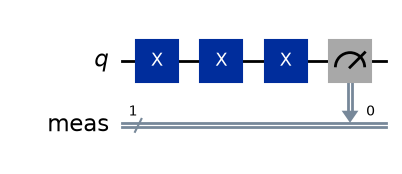

In [6]:
GATES = {"I": ["id"], "X": ["x"], "X X": ["x", "x"], "Z": ["z"]}
EXPECTED = {"I": I, "X": X, "X X": X @ X, "Z": Z}


def build_circuit(start_bit, gate_names, measure=True):
    """Prepare |start_bit>, apply the gates in order, and measure."""
    qubits = QuantumRegister(1, name="q")
    bits = ClassicalRegister(1, name="meas")
    circuit = QuantumCircuit(qubits, bits)
    if start_bit == 1:
        circuit.x(qubits[0])
    for gate in gate_names:
        getattr(circuit, gate)(qubits[0])
    if measure:
        circuit.measure(qubits, bits)
    return circuit


for label, gate_names in GATES.items():
    # Operator stores complex numbers (they appear from Notebook 04 on). Here
    # every imaginary part is 0, so .real keeps the plain real matrix.
    matrix = Operator(build_circuit(0, gate_names, measure=False)).data.real
    matches = np.allclose(matrix, EXPECTED[label])
    print(f"{label:4s} circuit matrix matches derived matrix: {matches}")

circuits = {}
for start_bit in (0, 1):
    for label, gate_names in GATES.items():
        circuits[(start_bit, label)] = build_circuit(start_bit, gate_names)
circuits[(1, "X X")].draw("mpl")

The prediction for each circuit uses the eigenvalue and flip rules: $I$, $X X$
and $Z$ return the starting bit, and $X$ returns the other bit.

In [7]:
def predicted_bit(start_bit, label):
    return 1 - start_bit if label == "X" else start_bit


for (start_bit, label) in circuits:
    prediction = predicted_bit(start_bit, label)
    print(f"start |{start_bit}>, apply {label:4s} -> predicted bit {prediction}")

start |0>, apply I    -> predicted bit 0
start |0>, apply X    -> predicted bit 1
start |0>, apply X X  -> predicted bit 0
start |0>, apply Z    -> predicted bit 0
start |1>, apply I    -> predicted bit 1
start |1>, apply X    -> predicted bit 0
start |1>, apply X X  -> predicted bit 1
start |1>, apply Z    -> predicted bit 1


### Execution

The same transpile, PUB and run steps as Notebook 00. The printout shows the
gates left after transpiling: `isa.count_ops()` returns how many gates of each
kind the ISA circuit contains. The transpiler is allowed to remove or merge
gates whose combined effect it can compute; watch what it does with $X\,X$.

In [8]:
isa_circuits = {}
for target in targets:
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    isa_circuits[target.label] = {
        key: pass_manager.run(c) for key, c in circuits.items()
    }
    print(target.label)
    for (start_bit, label), isa in isa_circuits[target.label].items():
        print(f"  start |{start_bit}>, {label:4s}: {dict(isa.count_ops())}")

pubs = {
    label: [(isa,) for isa in group.values()]
    for label, group in isa_circuits.items()
}

results = {}
for target in targets:
    job = target.sampler.run(pubs[target.label], shots=SETTINGS.shots)
    # wait() returns None if a hardware job failed or you stopped waiting.
    results[target.label] = target.wait(job)

aer
  start |0>, I   : {'measure': 1}
  start |0>, X   : {'x': 1, 'measure': 1}
  start |0>, X X : {'measure': 1}
  start |0>, Z   : {'z': 1, 'measure': 1}
  start |1>, I   : {'u3': 1, 'measure': 1}
  start |1>, X   : {'measure': 1}
  start |1>, X X : {'x': 1, 'measure': 1}
  start |1>, Z   : {'u3': 1, 'measure': 1}


The transpiled $X\,X$ circuit that starts in $|0\rangle$ has no gates left,
only the measurement: the transpiler used $X^2 = I$ and deleted both gates.
The same happened to the $X$ circuit that starts in $|1\rangle$, where the
preparation NOT and the applied $X$ cancel. In the $X\,X$ circuit that starts
in $|1\rangle$, the two applied $X$ gates cancel and leave the preparation
NOT, which stays a single `x`. A NOT followed by $I$ or $Z$ does not cancel,
so on the simulator the transpiler merged each such pair into one combined
gate, written `u3`: Qiskit's name for a general one-qubit gate described by
three angles, which Notebook 07 defines. None of this changes the
result, only how it is computed.

### Analysis

For each circuit we print the fraction of shots that returned the predicted
bit. On the simulator every fraction should be 1.000. The $Z$ rows give the
same counts as the $I$ rows, as the previous section predicted.

In [9]:
for label, result in results.items():
    if result is None:
        continue
    print(f"{label}, {SETTINGS.shots} shots:")
    for (start_bit, gate_label), pub_result in zip(circuits, result):
        counts = pub_result.data.meas.get_counts()
        expected = str(predicted_bit(start_bit, gate_label))
        fraction = counts.get(expected, 0) / SETTINGS.shots
        print(
            f"  start |{start_bit}>, {gate_label:4s}: counts {str(counts):14s}"
            f"  fraction on {expected} = {fraction:.3f}"
        )

aer, 4096 shots:
  start |0>, I   : counts {'0': 4096}     fraction on 0 = 1.000
  start |0>, X   : counts {'1': 4096}     fraction on 1 = 1.000
  start |0>, X X : counts {'0': 4096}     fraction on 0 = 1.000
  start |0>, Z   : counts {'0': 4096}     fraction on 0 = 1.000
  start |1>, I   : counts {'1': 4096}     fraction on 1 = 1.000


  start |1>, X   : counts {'0': 4096}     fraction on 0 = 1.000
  start |1>, X X : counts {'1': 4096}     fraction on 1 = 1.000
  start |1>, Z   : counts {'1': 4096}     fraction on 1 = 1.000


Every circuit returned its predicted bit. The two $Z$ circuits are
indistinguishable from the two $I$ circuits in the counts, even though $Z$
turned $|1\rangle$ into $-|1\rangle$.

## Exercises

1. Compute $\bar n = a\,a^\dagger$ by multiplying the two $2\times2$ matrices
   of Notebook 00, and check $\bar n|0\rangle$ and $\bar n|1\rangle$.
2. Show that $Z^2 = I$ using $Z = I - 2n$ and $n^2 = n$, without writing any
   matrix.
3. The operation "set the bit to 0, whatever its value" is $R = \bar n + a$.
   Write its matrix, check what it does to $|0\rangle$ and $|1\rangle$, and
   decide whether it has an inverse. What does that mean for running it as a
   gate that can be undone?
4. Compute $Z X$ and $X Z$ as matrices. Are they equal? Describe in words what
   each does to $|0\rangle$ and $|1\rangle$, applying the right factor first.
5. (Uses Notebook 00.) A two-qubit circuit starts in $|00\rangle$, applies
   NOT to qubit 0, then NOT to qubit 1, then $Z$ to qubit 0. Predict the
   counts key, and write the final state as a four-component vector,
   including its sign.
6. True or false: $a^\dagger a = I$, because setting a bit undoes clearing it.
   Give the reason.
7. (hardware) Set `skip_hardware=False` in the Setup cell and run the
   notebook. For each circuit, is the fraction on the predicted bit below
   1.000 by a real effect, according to the scatter rule of Notebook 00? Do
   the circuits whose predicted bit is 1 do worse than those whose predicted
   bit is 0?
8. (hardware) Build circuits that apply NOT $k = 1, 2, 4, 8, 16$ times to
   $|0\rangle$, and transpile them with `optimization_level=0`, which tells
   the transpiler not to simplify, so every gate runs. Plot the fraction of
   shots on the predicted bit against $k$ for Aer and for `ibm_rensselaer`.
   Does the hardware fraction fall as $k$ grows?

## What you can now do

1. Build the number operator $n = a^\dagger a$, its partner
   $\bar n = a\,a^\dagger$, and the identity $I = n + \bar n$ from set and
   clear.
2. Derive $X = a + a^\dagger$ and show $X^2 = I$.
3. Derive $Z = \bar n - n = I - 2n$, use $n = (I - Z)/2$, and explain why $Z$
   leaves the counts of a bitstring unchanged.
4. Predict the counts of a circuit of $I$, $X$ and $Z$ gates and check the
   prediction with the Encoding, Operator, Execution and Analysis steps.

## Solutions

**Check, outer products.** $|0\rangle\langle 0|$: it replaces $|0\rangle$ by
$|0\rangle$, and on $|1\rangle$ the inner product $\langle 0|1\rangle = 0$
gives the zero vector.

**Check, projectors.** $n\,\bar n = |1\rangle\langle 1|0\rangle\langle 0| = 0$,
because $\langle 1|0\rangle = 0$. A bit cannot be both 1 and 0, so asking both
questions removes every input.

**Check, Pauli X.** No. $X^2 = I$, and $I \ne X$. $X$ moves vectors to new
directions instead of keeping part of them.

**Check, Pauli Z.** $Z^2 = (I - 2n)^2 = I - 4n + 4n^2 = I - 4n + 4n = I$,
using $n^2 = n$ in the last step.

**Exercise 1.** $a\,a^\dagger = \begin{pmatrix}0&1\\0&0\end{pmatrix}\begin{pmatrix}0&0\\1&0\end{pmatrix}$.
Row 0 times column 0 is $0\cdot0 + 1\cdot1 = 1$, and every other entry is 0,
so $\bar n = \begin{pmatrix}1&0\\0&0\end{pmatrix}$. Then
$\bar n|0\rangle = (1, 0)^T = |0\rangle$ and $\bar n|1\rangle = (0, 0)^T = 0$.
**Check.** This matches $\bar n|x\rangle = (1 - x)|x\rangle$.

**Exercise 2.** Expand the square, keeping order:
$(I - 2n)(I - 2n) = I - 2n - 2n + 4n^2$. Replace $n^2$ by $n$:
$I - 4n + 4n = I$. **Check.** $Z$ multiplies by $\pm 1$, and $(\pm1)^2 = 1$.

**Exercise 3.** $R = \bar n + a = \begin{pmatrix}1&0\\0&0\end{pmatrix} + \begin{pmatrix}0&1\\0&0\end{pmatrix} = \begin{pmatrix}1&1\\0&0\end{pmatrix}$.
Then $R|0\rangle = |0\rangle$ (the $\bar n$ term) and $R|1\rangle = |0\rangle$
(the $a$ term). Its determinant is $1\cdot 0 - 1 \cdot 0 = 0$, so it has no
inverse. Two different inputs give the same output, so the output cannot tell
you what the input was, and no operation can undo $R$. Notebook 02 starts
from this observation: gates that can be undone cannot merge two inputs.

**Exercise 4.** $Z X = \begin{pmatrix}0&1\\-1&0\end{pmatrix}$ and
$X Z = \begin{pmatrix}0&-1\\1&0\end{pmatrix}$, so $Z X = -X Z$; they are not
equal. $Z X$ first flips, then signs: $|0\rangle \to |1\rangle \to -|1\rangle$
and $|1\rangle \to |0\rangle \to |0\rangle$. $X Z$ first signs, then flips:
$|0\rangle \to |0\rangle \to |1\rangle$ and
$|1\rangle \to -|1\rangle \to -|0\rangle$. Both flip the bit; they differ
only in which input gets the minus sign.

**Exercise 5.** After the two NOT gates the state is $|11\rangle$, the vector
$(0, 0, 0, 1)^T$. $Z$ on qubit 0 multiplies by $1 - 2x_0 = -1$, so the final
state is $-|11\rangle = (0, 0, 0, -1)^T$. The counts key is `"11"` on every
shot; the sign does not show.

**Exercise 6.** False. $a^\dagger a = n = |1\rangle\langle 1|$, which sends
$|0\rangle$ to the zero vector. Clearing a 0 fails, and setting afterward
cannot repair it. The identity needs both orders: $a^\dagger a + a\,a^\dagger = I$.

**Exercise 7.** Expect fractions slightly below 1.000 on hardware. The
scatter is about 0.002 for $p \approx 0.98$ and $N = 4096$, so a gap of more
than three times that, about 0.007, is a real effect by the scatter rule.
Circuits whose predicted bit is 1 usually do worse, because of the readout
error of Notebook 00: a 1 is misread as 0 more often than a 0 is misread
as 1.

**Exercise 8.** A sketch: build each circuit with `build_circuit(0, ["x"] * k)`
and transpile it with

```python
pass_manager = generate_preset_pass_manager(
    backend=target.backend, optimization_level=0
)
```

On Aer every fraction is 1.000. On hardware each NOT gate has a small error,
so the fraction should fall slowly as $k$ grows. Odd $k$ end on 1 and even
$k$ on 0, so part of the difference between neighbors comes from the readout
of 1 versus 0 (the readout error of Notebook 00), not from the number of
gates. Compare odd $k$
with odd $k$.

## Terms introduced in this notebook

| Term | Meaning |
|---|---|
| operator | a square matrix that acts on state vectors; $2^n \times 2^n$ for $n$ bits |
| bra | $\langle v\rvert$, the transpose of the ket $\lvert v\rangle$ (real vectors; Notebook 04 adds complex conjugation) |
| inner product | $\langle u \vert v\rangle$, a row times a column: a number |
| outer product | $\lvert u\rangle\langle v\rvert$, a column times a row: an operator that turns $\lvert v\rangle$ into $\lvert u\rangle$ |
| number operator | $n = a^\dagger a = \lvert 1\rangle\langle 1\rvert$, with $n\lvert x\rangle = x\lvert x\rangle$ |
| $\bar n$ | $a\,a^\dagger = \lvert 0\rangle\langle 0\rvert$, with $\bar n\lvert x\rangle = (1-x)\lvert x\rangle$ |
| projector | an operator $P$ with $P^2 = P$ |
| completeness | $n + \bar n = I$ |
| Pauli X | $X = a + a^\dagger$, the NOT operator |
| Pauli Z | $Z = \bar n - n = I - 2n$; eigenvalue $+1$ on $\lvert 0\rangle$ and $-1$ on $\lvert 1\rangle$ |
| Pauli operators | $X$, $Z$, and (from Notebook 04) $Y$ |
| Z-basis measurement | the measurement of Notebook 00; it reports which eigenvector of $Z$ a qubit is in |